# RRAM 모델 1단계 — 파이썬 레퍼런스 검증

`rram_model.py`(DATE 2015 논문 식 (1)–(11), 매뉴얼 Table 3 기본값)를 검증하고 2단계용 golden CSV를 만든다.
가정 목록은 `../ASSUMPTIONS.md` (A1, A2, …).

| 절 | 내용 |
|---|---|
| 0 | 설정 |
| 1 | DC 스윕 I-V (매뉴얼 Fig. 3 비교) |
| 2 | 램프 속도 의존성 (SET 전압 이동) |
| 3 | 펄스 SET/RESET (매뉴얼 Fig. 4 비교, CP 포함) |
| 4 | 0.2 V 읽기 — LRS/HRS 저항 |
| 5 | 고정 상태 모드 (갭·필라멘트 면적 지정, 스위칭 없음) |
| 6 | 필라멘트 밀도 n_f·A_cell 병렬 |
| 7 | 변동성 (식 (8)–(11)) — 사이클 겹침 + 분포 |
| 8 | golden CSV 저장 |

In [1]:
import time
from dataclasses import replace
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import rram_model as rm

P = rm.DEFAULT
RS = rm.RS_SWEEP	# I-V 스윕
RS_P = rm.RS_PULSE	# 펄스
GOLDEN = Path("golden")
GOLDEN.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("N filaments =", P.N, "| Rs sweep =", RS, "ohm | Rs pulse =", RS_P, "ohm")

N filaments = 1 | Rs sweep = 18000.0 ohm | Rs pulse = 10000.0 ohm


## 1. DC 스윕 I-V

0 → +2.5 → 0 → −2.5 → 0 V, 각 구간 100 µs (매뉴얼 샘플 덱의 100 µs 램프와 같은 크기). 초기 상태는 Table 3의 SET 초기값 `x0 = L0, w0 = 0.5 nm`.
첫 사이클(포밍에 가까움)과 그 끝 상태에서 시작한 두 번째 사이클을 같이 그린다.

In [2]:
vf, t_end, corners = rm.sweep_waveform(2.5, -2.5, 100e-6)
t0 = time.time()
sw1 = rm.simulate(vf, t_end, *rm.INIT_HRS, Rs=RS, corners=corners)
sw2 = rm.simulate(vf, t_end, sw1.x[-1], sw1.w[-1], Rs=RS, corners=corners)
print(f"{time.time() - t0:.1f} s, nfev = {sw1.info['nfev']} + {sw2.info['nfev']}")
for name, r in (("cycle 1", sw1), ("cycle 2", sw2)):
	vs, vr = rm.switching_voltage(r)
	print(f"{name}: V_SET = {vs:.2f} V, V_RESET(peak |I|) = {vr:.2f} V, I_max = {r.i.max() * 1e6:.0f} uA")

3.7 s, nfev = 4254 + 4071
cycle 1: V_SET = 1.24 V, V_RESET(peak |I|) = -1.46 V, I_max = 102 uA
cycle 2: V_SET = 2.07 V, V_RESET(peak |I|) = -1.43 V, I_max = 105 uA


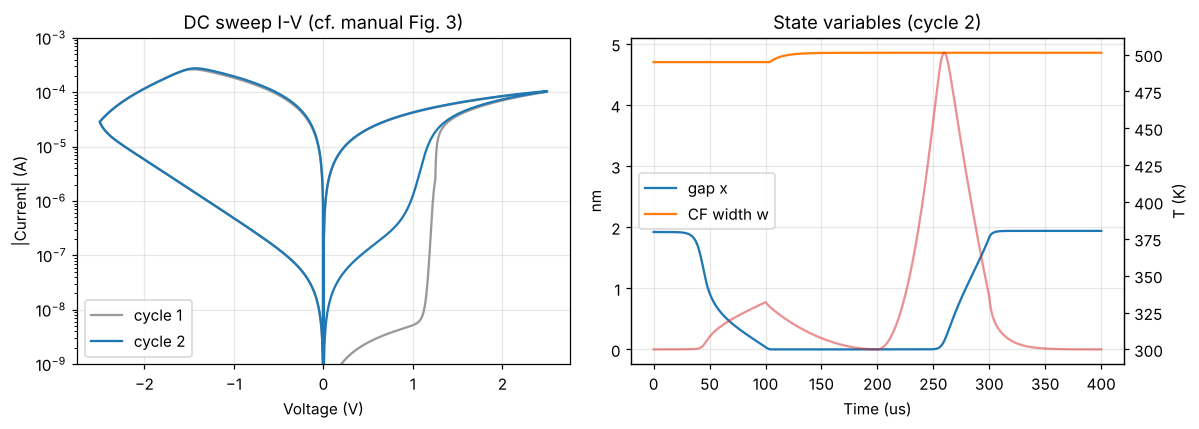

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for r, lab, c in ((sw1, "cycle 1", "0.6"), (sw2, "cycle 2", "C0")):
	ax[0].semilogy(r.v_app, np.abs(r.i), color=c, label=lab)
ax[0].set(xlabel="Voltage (V)", ylabel="|Current| (A)", ylim=(1e-9, 1e-3), title="DC sweep I-V (cf. manual Fig. 3)")
ax[0].legend()
t_us = sw2.t * 1e6
ax[1].plot(t_us, sw2.x * 1e9, label="gap x")
ax[1].plot(t_us, sw2.w * 1e9, label="CF width w")
ax[1].set(xlabel="Time (us)", ylabel="nm", title="State variables (cycle 2)")
ax2 = ax[1].twinx()
ax2.plot(t_us, sw2.T, color="C3", alpha=0.5, label="T")
ax2.set_ylabel("T (K)")
ax2.grid(False)
ax[1].legend(loc="center left")
plt.tight_layout()

**주의:** RESET에서 필라멘트 폭이 줄지 않으므로(A16) 2번째 사이클 이후 거동은 근사다.

**확인:** 급격한 SET(전류가 compliance ≈ 100 µA로 포화) + 점진적 RESET. 매뉴얼 Fig. 3의 정성적 형태(양의 SET, 음의 점진적 RESET, LRS/HRS 수 배~수십 배 차이)와 같다.

## 2. 램프 속도 의존성

같은 진폭에서 램프 시간을 10 µs / 100 µs / 1 ms로 바꾼다. 식 (1)은 열활성 과정이므로 느린 램프일수록 낮은 전압에서 SET되어야 한다.

t_ramp =     10 us: V_SET = 1.480 V, V_RESET = -1.815 V


t_ramp =    100 us: V_SET = 1.240 V, V_RESET = -1.455 V


t_ramp =   1000 us: V_SET = 1.000 V, V_RESET = -1.270 V


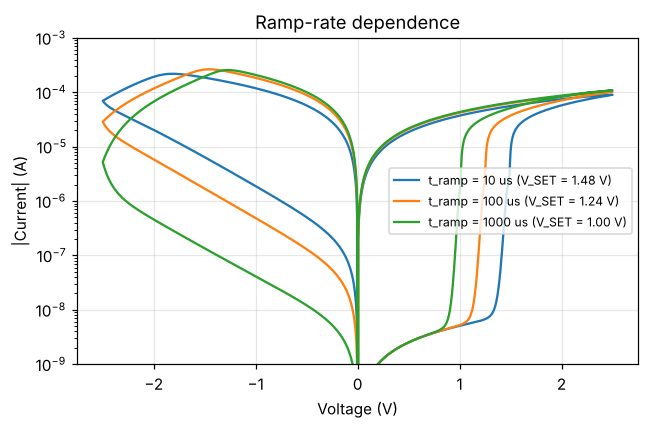

In [4]:
ramps = [10e-6, 100e-6, 1e-3]
ramp_res = {}
fig, ax = plt.subplots(figsize=(6, 4))
for k, tr in enumerate(ramps):
	vf_r, te_r, c_r = rm.sweep_waveform(2.5, -2.5, tr)
	r = rm.simulate(vf_r, te_r, *rm.INIT_HRS, Rs=RS, corners=c_r)
	ramp_res[tr] = r
	vs, vr = rm.switching_voltage(r)
	ax.semilogy(r.v_app, np.abs(r.i), color=f"C{k}", label=f"t_ramp = {tr * 1e6:g} us (V_SET = {vs:.2f} V)")
	print(f"t_ramp = {tr * 1e6:6g} us: V_SET = {vs:.3f} V, V_RESET = {vr:.3f} V")
ax.set(xlabel="Voltage (V)", ylabel="|Current| (A)", ylim=(1e-9, 1e-3), title="Ramp-rate dependence")
ax.legend(fontsize=8)
plt.tight_layout()

## 3. 펄스 SET / RESET

매뉴얼 AC 샘플 덱과 같은 파형: 2 V, rise/fall 10 ns, 폭 80 ns, 총 100 ns. 이 절은 CP를 상태변수로 포함한다 (A11).
SET은 HRS 초기값 + 직렬 저항 Rs = 10 kΩ (펄스 기본값), RESET은 LRS 초기값(`x0 = 0, w0 = WCF`) + Rs_reset = 0, 극성 반대.

SET: gap closes at t = 12.3 ns, I(80 ns) = 85 uA
RESET: |I| peak = 448 uA -> |I(85 ns)| = 237 uA, T_max = 742 K


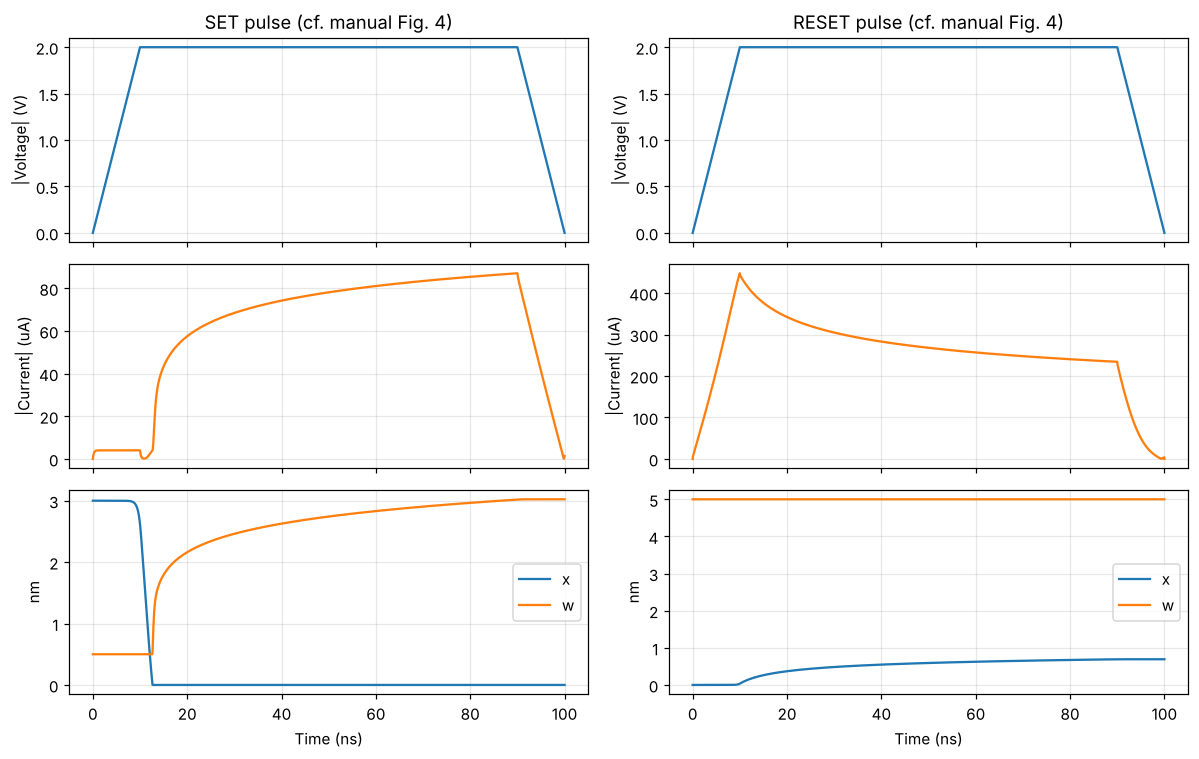

In [5]:
pulse = {}
for name, vp, init in (("set", 2.0, rm.INIT_HRS), ("reset", -2.0, rm.INIT_LRS)):
	vf_p, te_p, c_p = rm.pulse_waveform(vp, 10e-9, 80e-9, 100e-9)
	pulse[name] = rm.simulate(vf_p, te_p, *init, Rs=RS_P, include_cp=True, corners=c_p, max_step=0.1e-9)
ps, pr = pulse["set"], pulse["reset"]
k = np.argmax(ps.x < P.a)
print(f"SET: gap closes at t = {ps.t[k] * 1e9:.1f} ns, I(80 ns) = {np.interp(80e-9, ps.t, ps.i) * 1e6:.0f} uA")
print(f"RESET: |I| peak = {np.abs(pr.i).max() * 1e6:.0f} uA -> |I(85 ns)| = {abs(np.interp(85e-9, pr.t, pr.i)) * 1e6:.0f} uA, T_max = {pr.T.max():.0f} K")

fig, ax = plt.subplots(3, 2, figsize=(11, 7), sharex=True)
for j, (name, r) in enumerate((("SET", ps), ("RESET", pr))):
	tn = r.t * 1e9
	ax[0, j].plot(tn, np.abs(r.v_app), color="C0")
	ax[0, j].set(ylabel="|Voltage| (V)", title=f"{name} pulse (cf. manual Fig. 4)")
	ax[1, j].plot(tn, np.abs(r.i) * 1e6, color="C1")
	ax[1, j].set(ylabel="|Current| (uA)")
	ax[2, j].plot(tn, r.x * 1e9, label="x")
	ax[2, j].plot(tn, r.w * 1e9, label="w")
	ax[2, j].set(ylabel="nm", xlabel="Time (ns)")
	ax[2, j].legend()
plt.tight_layout()

**확인:** SET은 약 10–15 ns 안에 갭이 닫히고, RESET 전류는 수백 µA에서 펄스 동안 점진적으로 감소한다. 시간 스케일은 Fig. 4(0–100 ns)와 같다.
SET 펄스 전류는 Rs = 10 kΩ에서 Fig. 4(1T1R, ~100 µA)와 비슷한 크기가 되도록 했다.

## 4. 0.2 V 읽기 — LRS / HRS 저항

스위칭 없이(상태 고정) 0.2 V에서 셀 저항(RL, RH 포함)을 계산한다.

In [6]:
j_lrs = np.argmin(np.abs(sw2.t - 2 * 100e-6))	# SET 구간 끝 (0 V로 돌아온 시점)
reads = {
	"LRS after DC SET (cycle 2)": (sw2.x[j_lrs], sw2.w[j_lrs]),
	"HRS after DC RESET (cycle 2)": (sw2.x[-1], sw2.w[-1]),
	"after SET pulse": (ps.x[-1], ps.w[-1]),
	"after RESET pulse": (pr.x[-1], pr.w[-1]),
	"Table 3 LRS init (x=0, w=WCF)": rm.INIT_LRS,
	"Table 3 HRS init (x=L0, w=0.5nm)": rm.INIT_HRS,
}
read_rows = []
for name, (x, w) in reads.items():
	R = rm.read_resistance(x, w, P, 0.2)
	read_rows.append((x, w, R))
	print(f"{name:34s} x = {x * 1e9:5.2f} nm, w = {w * 1e9:4.2f} nm -> R(0.2 V) = {R:10.4g} ohm")
R_lrs = rm.read_resistance(*reads["LRS after DC SET (cycle 2)"])
R_hrs = rm.read_resistance(*reads["HRS after DC RESET (cycle 2)"])
print(f"HRS/LRS ratio (DC cycle 2) = {R_hrs / R_lrs:.0f}")

LRS after DC SET (cycle 2)         x =  0.00 nm, w = 4.86 nm -> R(0.2 V) =       5348 ohm
HRS after DC RESET (cycle 2)       x =  1.94 nm, w = 4.86 nm -> R(0.2 V) =  4.742e+06 ohm
after SET pulse                    x =  0.00 nm, w = 3.02 nm -> R(0.2 V) =  1.377e+04 ohm
after RESET pulse                  x =  0.69 nm, w = 5.00 nm -> R(0.2 V) =  3.362e+04 ohm
Table 3 LRS init (x=0, w=WCF)      x =  0.00 nm, w = 5.00 nm -> R(0.2 V) =       5044 ohm
Table 3 HRS init (x=L0, w=0.5nm)   x =  3.00 nm, w = 0.50 nm -> R(0.2 V) =  1.988e+08 ohm
HRS/LRS ratio (DC cycle 2) = 887


## 5. 고정 상태 모드

갭 크기 `x`와 필라멘트 면적 `A_CF`(= π w²/4, w는 지름 — A1)를 직접 지정하고 스위칭 없이 읽기 I-V를 본다.

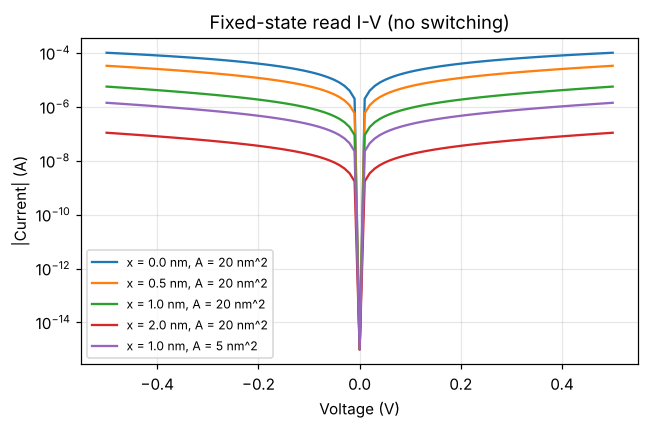

In [7]:
v_fix = np.linspace(-0.5, 0.5, 101)
fixed_cases = [(0.0, 20e-18), (0.5e-9, 20e-18), (1.0e-9, 20e-18), (2.0e-9, 20e-18), (1.0e-9, 5e-18)]
fixed_iv = {}
fig, ax = plt.subplots(figsize=(6, 4))
for k, (x, A) in enumerate(fixed_cases):
	i = rm.iv_fixed_state(v_fix, x, A, P)
	fixed_iv[(x, A)] = i
	ax.semilogy(v_fix, np.abs(i) + 1e-15, color=f"C{k}", label=f"x = {x * 1e9:.1f} nm, A = {A * 1e18:.0f} nm^2")
ax.set(xlabel="Voltage (V)", ylabel="|Current| (A)", title="Fixed-state read I-V (no switching)")
ax.legend(fontsize=8)
plt.tight_layout()

## 6. 필라멘트 밀도 — N = round(n_f · A_cell) 병렬

동일 필라멘트 N개 병렬(A10). compliance는 총전류 N·I로 푼다. N = 1, 4로 비교.

N = 4


I_max: N=1 102 uA, N=4 99 uA (both limited by Rs)


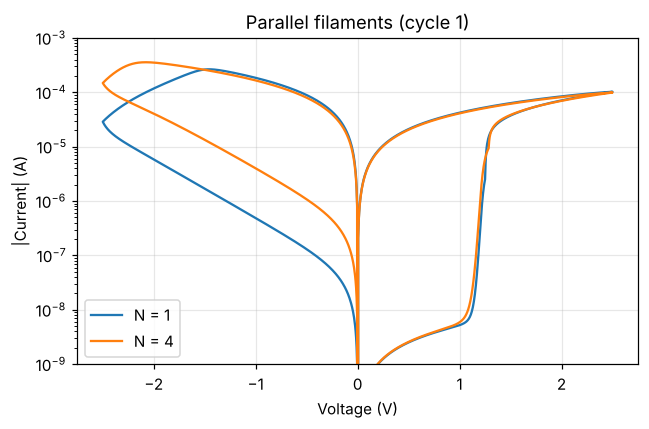

In [8]:
p4 = replace(P, n_f=4e16)	# 10 nm x 10 nm 안에 필라멘트 4개
print("N =", p4.N)
sw_n4 = rm.simulate(vf, t_end, *rm.INIT_HRS, p=p4, Rs=RS, corners=corners)
fig, ax = plt.subplots(figsize=(6, 4))
ax.semilogy(sw1.v_app, np.abs(sw1.i), label="N = 1")
ax.semilogy(sw_n4.v_app, np.abs(sw_n4.i), label="N = 4")
ax.set(xlabel="Voltage (V)", ylabel="|Current| (A)", ylim=(1e-9, 1e-3), title="Parallel filaments (cycle 1)")
ax.legend()
plt.tight_layout()
print(f"I_max: N=1 {sw1.i.max() * 1e6:.0f} uA, N=4 {sw_n4.i.max() * 1e6:.0f} uA (both limited by Rs)")

## 7. 변동성 (Dynamic Model)

- 사이클마다 Ea, Ei, Eh를 정규분포로 다시 뽑는다 — 식 (10), (11), σ는 A13
- 사이클 안에서는 식 (8), (9)의 χ(t)를 0.2 µs마다 새로 뽑는 piecewise-constant 가우시안으로 넣는다 (A12)
- 각 사이클은 직전 사이클의 끝 상태에서 시작한다

In [9]:
N_CYC = 20
rng = np.random.default_rng(2015)
var = rm.Variability()
x, w = sw1.x[-1], sw1.w[-1]	# 첫 사이클(포밍)이 남긴 HRS에서 시작
cyc, r_lrs, r_hrs, v_set = [], [], [], []
t0 = time.time()
for c in range(N_CYC):
	pc = rm.sample_cycle_params(P, var, rng)
	r = rm.simulate(vf, t_end, x, w, p=pc, Rs=RS, corners=corners, noise_dt=0.2e-6, rng=rng)
	j = np.argmin(np.abs(r.t - 2 * 100e-6))
	cyc.append(r)
	r_lrs.append(rm.read_resistance(r.x[j], r.w[j], pc))
	r_hrs.append(rm.read_resistance(r.x[-1], r.w[-1], pc))
	v_set.append(rm.switching_voltage(r, pc)[0])
	x, w = r.x[-1], r.w[-1]
print(f"{N_CYC} cycles in {time.time() - t0:.0f} s")
print(f"R_LRS median {np.median(r_lrs):.3g} ohm, R_HRS median {np.median(r_hrs):.3g} ohm, V_SET {np.mean(v_set):.2f} +- {np.std(v_set):.2f} V")

20 cycles in 200 s
R_LRS median 8.75e+03 ohm, R_HRS median 3.47e+06 ohm, V_SET 1.78 +- 0.32 V


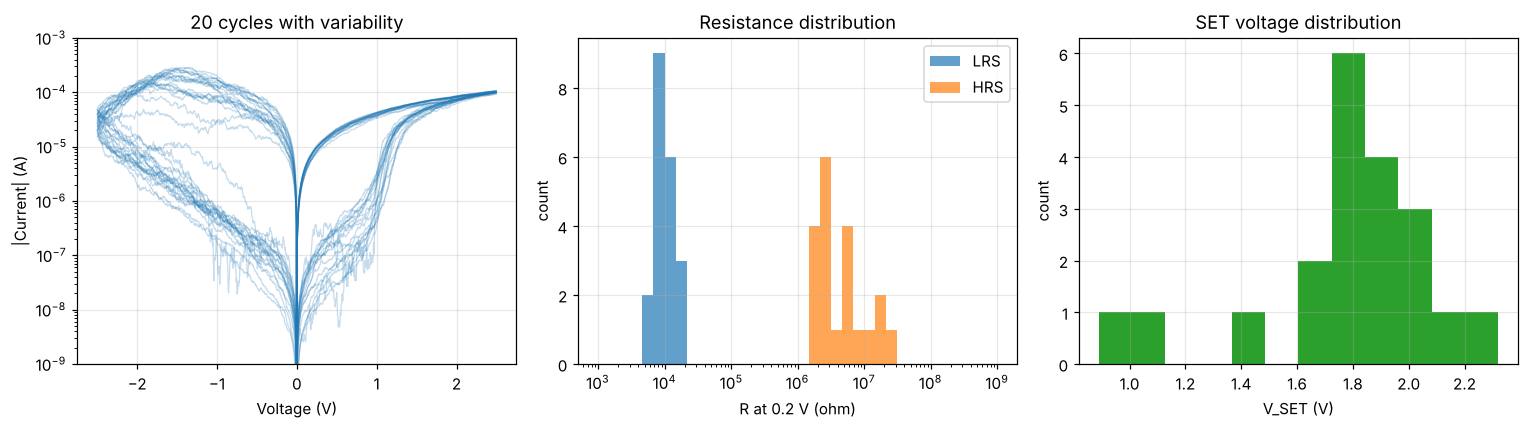

In [10]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for r in cyc:
	ax[0].semilogy(r.v_app, np.abs(r.i), color="C0", alpha=0.25, lw=0.8)
ax[0].set(xlabel="Voltage (V)", ylabel="|Current| (A)", ylim=(1e-9, 1e-3), title=f"{N_CYC} cycles with variability")
bins = np.logspace(3, 9, 37)
ax[1].hist(r_lrs, bins=bins, alpha=0.7, label="LRS")
ax[1].hist(r_hrs, bins=bins, alpha=0.7, label="HRS")
ax[1].set(xscale="log", xlabel="R at 0.2 V (ohm)", ylabel="count", title="Resistance distribution")
ax[1].legend()
ax[2].hist(v_set, bins=12, color="C2")
ax[2].set(xlabel="V_SET (V)", ylabel="count", title="SET voltage distribution")
plt.tight_layout()

## 8. golden CSV 저장 (2단계 정답지)

결정론적 경우만 저장한다. 변동성 결과는 난수 생성기에 의존하므로 golden에서 뺀다. 각 파일 설명은 `golden/README.md`.

In [11]:
hdr = rm.CSV_HEADER
np.savetxt(GOLDEN / "sweep_cycle1.csv", sw1.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "sweep_cycle2.csv", sw2.table(), delimiter=",", header=hdr, comments="")
for tr, r in ramp_res.items():
	np.savetxt(GOLDEN / f"sweep_ramp_{tr * 1e6:g}us.csv", r.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "pulse_set.csv", ps.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "pulse_reset.csv", pr.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "sweep_n4.csv", sw_n4.table(), delimiter=",", header=hdr, comments="")
np.savetxt(GOLDEN / "read_resistance.csv", np.array(read_rows), delimiter=",", header="x_m,w_m,R_ohm", comments="")

rows = []
for (x, A), i in fixed_iv.items():
	for vk, ik in zip(v_fix, i):
		rows.append((x, A, vk, ik))
np.savetxt(GOLDEN / "fixed_state_iv.csv", np.array(rows), delimiter=",", header="x_m,A_m2,v_V,i_A", comments="")

# 기본 함수 확인: (v, x, w) 격자에서의 단일 필라멘트 전류, RL/RH/Rs 없음
rows = []
for x in (0.0, 0.5e-9, 1.5e-9, 3e-9):
	for w in (0.5e-9, 2e-9, 5e-9):
		for vk in (-2.0, -0.5, -0.1, 0.05, 0.2, 1.0, 2.5):
			i_f, vg = rm.filament_current(vk, x, w, P)
			rows.append((vk, x, w, i_f, vg))
np.savetxt(GOLDEN / "filament_current.csv", np.array(rows), delimiter=",", header="v_V,x_m,w_m,i_A,v_gap_V", comments="")
print(sorted(p.name for p in GOLDEN.glob("*.csv")))

['filament_current.csv', 'fixed_state_iv.csv', 'pulse_reset.csv', 'pulse_set.csv', 'read_resistance.csv', 'sweep_cycle1.csv', 'sweep_cycle2.csv', 'sweep_n4.csv', 'sweep_ramp_1000us.csv', 'sweep_ramp_100us.csv', 'sweep_ramp_10us.csv']
